# Experiment 1: PD outcomes and evaluation

Which continued-pretraining choices improve or harm transfer to held-out credit tables? Start with final five-fold benchmark effects, retain the complete configuration grid, then examine table heterogeneity, probability or regression quality, and non-credit retention. The study is descriptive: an observed grid maximum is not an independently validated deployment recipe.

## 0. Evidence and scope

Positive effects consistently mean improvement. A favorable contrast between two CPT choices can mean less damage; only a positive CPT-versus-original effect shows an observed gain over the starting weights. TabICLv2 outcomes retain the numerical-policy qualification documented in experiment 0.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, publication as pub, diagnostics as dg
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('experiment1/03_results_pd')
report = cp.NotebookReport('Experiment 1: PD outcomes and evaluation', sink=sink)
TRACK = 'pd'
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.')

from src.visualize import dashboards as db, choice_effects as ce
from src.visualize import finishing as finish
from src.visualize import prediction_diagnostics as pred


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Evidence and benchmark eligibility

Each final comparison requires five finite, successful outer folds and paired original predictions. All recipes shown within one model use the same tables across the displayed metrics. Non-credit summaries additionally require all four CPT partitions.

In [2]:
run = cp.load_campaign(1, TRACK)
grid = ce.benchmark_grid(run)
report.table('Available evidence', pub.availability(run))
report.add('1. Evidence and benchmark eligibility', cp.coverage_summary(run))

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project trajectory diagnostics
4,Benchmark folds,11715,Project final evaluation


## 2. Which CPT choices help?

Compare L2-SP anchoring with no anchoring, a frozen transformer backbone with all parameters updated, and each larger learning rate with the lowest rate. Match every other setting before averaging within table, then weight tables equally. Keep model identities and metric scales separate; opposite effects must not cancel in a pooled model average.

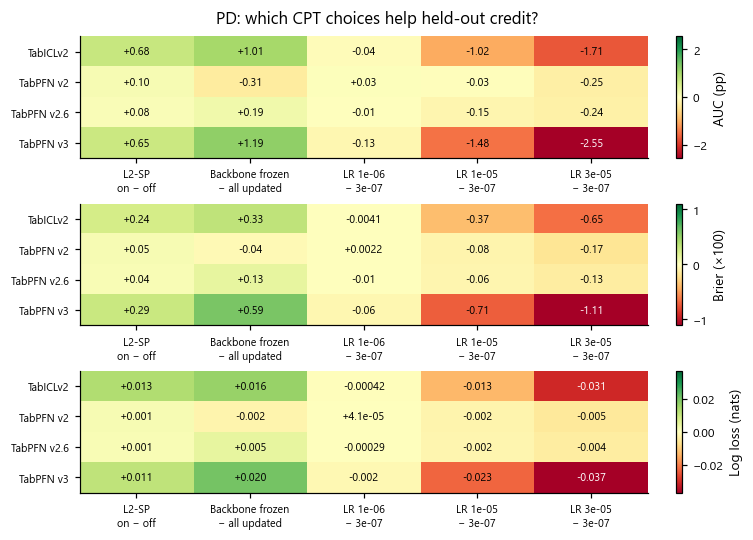

PD. Final five-fold benchmark contrasts between CPT choices. 17 complete tables per model. Each cell first pairs the same table and all other recipe settings, averages those matched differences within table, then weights tables equally. Positive values favor the named alternative. A favorable choice contrast can mean less deterioration; it does not establish a gain over original weights. Anchoring and scope contrasts average all four rates; each rate contrast averages both anchoring and scope settings. Models and metrics remain separate. Each model uses the same recipe-complete table cohort across displayed metrics. AUC contrasts are percentage points; Brier contrasts are multiplied by 100. Brier and log-loss signs are reversed so reductions are positive. Colors are symmetric about zero within each metric panel. These are descriptive fixed-grid contrasts, not causal architecture comparisons. TabICLv2 PD effects retain the selected-table numerical-policy qualification.

In [3]:
cp.show(sink, ce.plot_choices(grid, TRACK), track=TRACK)
report.add('2. Which CPT choices help?', 'The figure shows alternative minus reference, with the sign oriented toward improvement. Complete marginal effects at each choice level and every matched table contrast accompany it. These descriptive comparisons concern the observed fixed grid; recipe cells and folds are not independent replications.')

## 3. Combinations, credit transfer and non-credit retention

Average choice effects can hide interactions. Each matrix retains all learning-rate, anchoring and update-scope combinations. Green means CPT improves on its own original model; red means it worsens. The final figure compares credit and non-credit effects for the same recipe. Small values remain printed, and the full summary records how many tables improve in every cell.

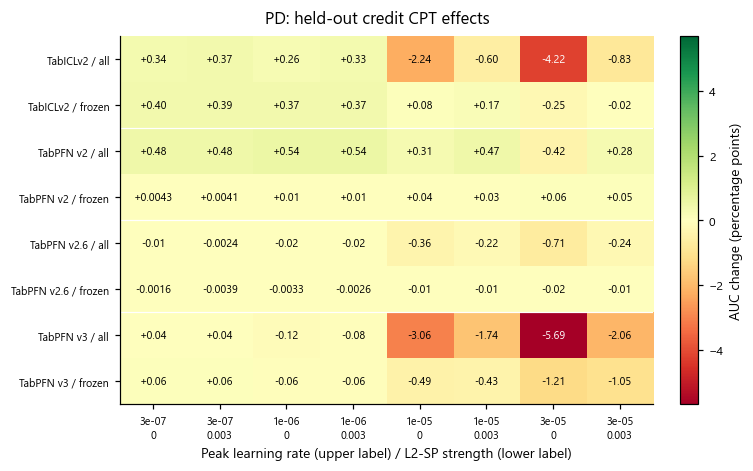

PD. Final five-fold benchmark: AUC change (percentage points). 17 complete tables per model. Each cell is the equal-table mean CPT effect relative to its own original weights; positive values favor CPT. All planned rate × anchoring × scope combinations are shown on one common table cohort within each model. Rows marked all update normally trainable parameters; frozen rows freeze the dominant transformer stack while retaining configured surrounding components. Neither mode uses LoRA. Colors share one symmetric scale; printed values retain small effects. Five outer folds are averaged within table. Observed maxima are exploratory grid outcomes, not independently validated selected recipes. TabICLv2 PD effects retain the selected-table numerical-policy qualification.

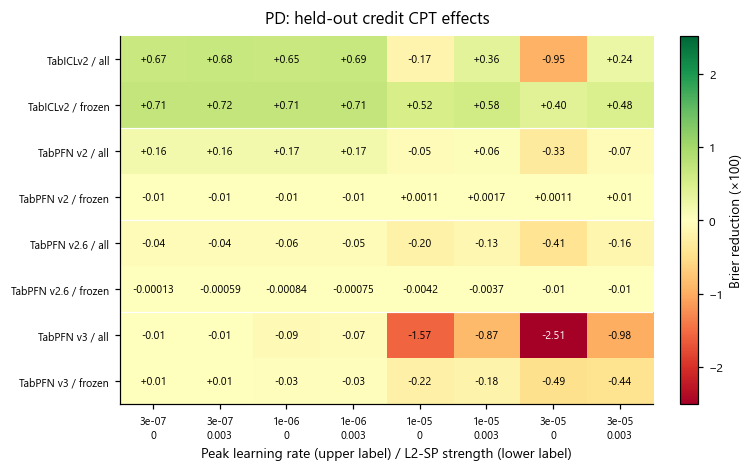

PD. Final five-fold benchmark: Brier reduction (×100). 17 complete tables per model. Each cell is the equal-table mean CPT effect relative to its own original weights; positive values favor CPT. All planned rate × anchoring × scope combinations are shown on one common table cohort within each model. Rows marked all update normally trainable parameters; frozen rows freeze the dominant transformer stack while retaining configured surrounding components. Neither mode uses LoRA. Colors share one symmetric scale; printed values retain small effects. Five outer folds are averaged within table. Observed maxima are exploratory grid outcomes, not independently validated selected recipes. TabICLv2 PD effects retain the selected-table numerical-policy qualification.

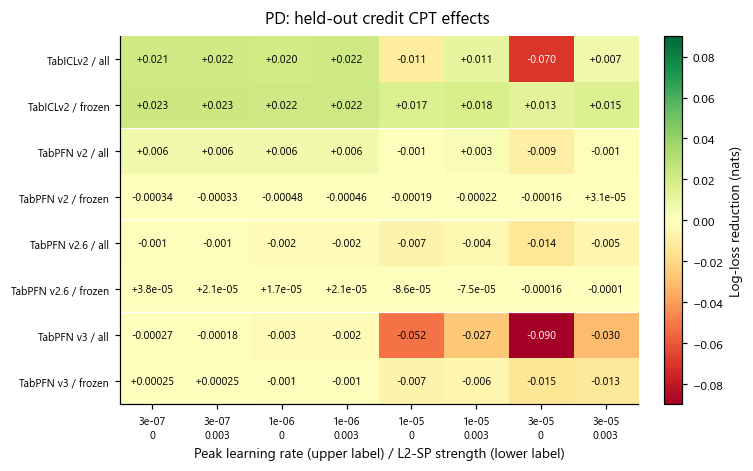

PD. Final five-fold benchmark: Log-loss reduction (nats). 17 complete tables per model. Each cell is the equal-table mean CPT effect relative to its own original weights; positive values favor CPT. All planned rate × anchoring × scope combinations are shown on one common table cohort within each model. Rows marked all update normally trainable parameters; frozen rows freeze the dominant transformer stack while retaining configured surrounding components. Neither mode uses LoRA. Colors share one symmetric scale; printed values retain small effects. Five outer folds are averaged within table. Observed maxima are exploratory grid outcomes, not independently validated selected recipes. TabICLv2 PD effects retain the selected-table numerical-policy qualification.

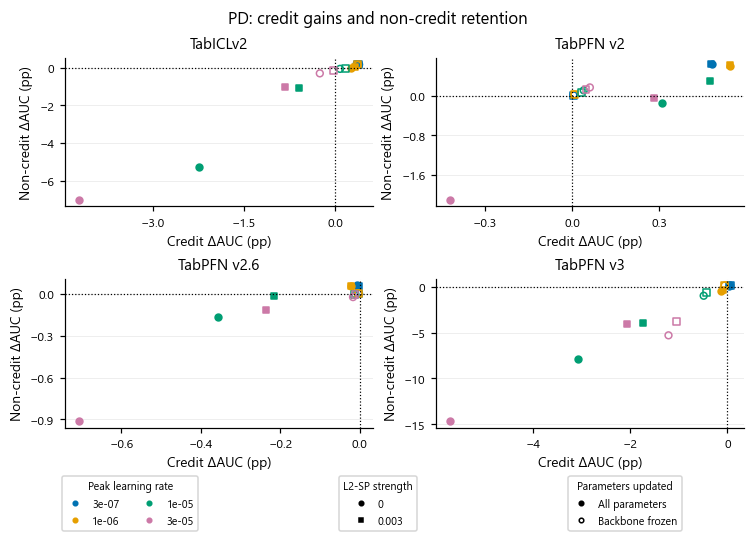

PD. Final five-fold benchmark effects relative to original weights, matched by CPT recipe across the two domains. Credit: 17 complete tables per model. Non-credit: 4 complete tables per model. The upper-right quadrant improves both credit and non-credit means; the lower-right improves credit while reducing retention. Each domain weights its recipe-complete tables equally; non-credit effects first average all four matched CPT partitions. Axis limits vary across base models. Each of the 16 fixed-grid recipes remains visible through rate, anchoring and scope encodings; overlapping outcomes may coincide. The finite non-credit panel does not establish general retention. TabICLv2 PD effects retain the selected-table numerical-policy qualification.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,partitions
3264,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46905,ood,roc_auc,-0.002284,4
3265,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46947,ood,roc_auc,-0.001244,4
3266,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46952,ood,roc_auc,-0.000213,4
3267,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46956,ood,roc_auc,0.010459,4
3268,TabICLv2,3.000000e-07,0.000,True,one_sample,openml_46905,ood,roc_auc,-0.001388,4
...,...,...,...,...,...,...,...,...,...,...
4027,TabPFN v3,3.000000e-05,0.003,False,one_sample,openml_46956,ood,log_loss,-0.022718,4
4028,TabPFN v3,3.000000e-05,0.003,True,one_sample,openml_46905,ood,log_loss,-0.032606,4
4029,TabPFN v3,3.000000e-05,0.003,True,one_sample,openml_46947,ood,log_loss,-0.001903,4
4030,TabPFN v3,3.000000e-05,0.003,True,one_sample,openml_46952,ood,log_loss,-0.023381,4


,domain,metric,base,learning_rate,l2sp_lambda,frozen,sampling,mean,median,q25,q75,tables,improved
0,credit,brier_score,TabICLv2,3.000000e-07,0.000,False,one_sample,0.006658,-0.000176,-0.000300,0.000093,17,6
1,credit,brier_score,TabICLv2,3.000000e-07,0.000,True,one_sample,0.007149,0.000012,-0.000122,0.000114,17,10
2,credit,brier_score,TabICLv2,3.000000e-07,0.003,False,one_sample,0.006803,-0.000083,-0.000249,0.000082,17,7
3,credit,brier_score,TabICLv2,3.000000e-07,0.003,True,one_sample,0.007164,-0.000002,-0.000108,0.000148,17,8
4,credit,brier_score,TabICLv2,1.000000e-06,0.000,False,one_sample,0.006536,-0.000394,-0.000713,0.000200,17,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,ood,roc_auc,TabPFN v3,1.000000e-05,0.003,True,one_sample,-0.006585,-0.002835,-0.009171,-0.000249,4,1
380,ood,roc_auc,TabPFN v3,3.000000e-05,0.000,False,one_sample,-0.146199,-0.126417,-0.182265,-0.090351,4,0
381,ood,roc_auc,TabPFN v3,3.000000e-05,0.000,True,one_sample,-0.052973,-0.042764,-0.087460,-0.008276,4,0
382,ood,roc_auc,TabPFN v3,3.000000e-05,0.003,False,one_sample,-0.040499,-0.040627,-0.064353,-0.016773,4,0


In [4]:
for metric in ('roc_auc', 'brier_score', 'log_loss'):
    cp.show(sink, ce.plot_combinations(grid, TRACK, metric), track=TRACK)
cp.show(sink, ce.plot_transfer_retention(grid, TRACK), track=TRACK)
report.table('Non-credit effects for every complete recipe and metric', grid[grid.domain.eq('ood')] if not grid.empty else grid)
report.table('Every recipe: mean, median, quartiles and positive table count', ce.recipe_summary(grid))
report.add('3. Combinations, credit transfer and non-credit retention', 'All parameters means all normally trainable weights are updated. Backbone frozen means the dominant transformer stack is frozen while surrounding configured components remain trainable. Neither mode uses LoRA. Five folds are averaged within each table; tables receive equal weight. Non-credit retention is measured on a finite panel, not all possible domains. A high observed cell does not identify an unbiased test-selected winner.')

## 4. Fixed reference and table heterogeneity

Use the predefined conservative recipe to assess the size, consistency and source sensitivity of transfer. It is not chosen from the best test outcomes. Conditional intervals and public-source checks assess uncertainty under the stated design; they do not turn overlapping partitions into independent experiments.

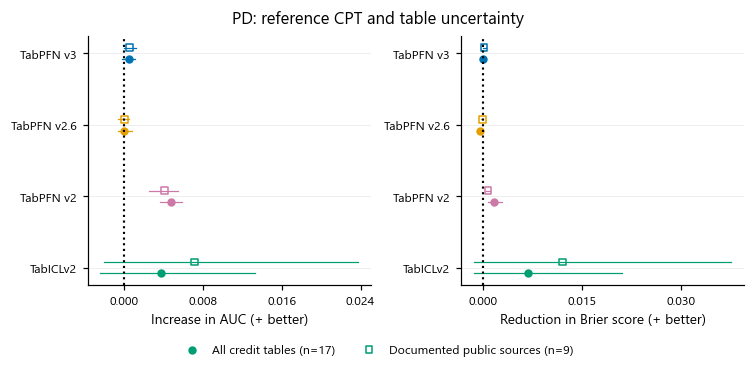

PD. Mean paired benchmark effects of the predefined full-update CPT reference and 95% conditional table-bootstrap intervals. Positive effects favor CPT; RMSE is reported as fractional error reduction. Filled circles include all credit tables; open squares retain documented public sources. Each table contributes the mean of five paired outer folds. Source restriction is based on provenance, not scores. Intervals do not capture training-seed uncertainty or establish source independence.

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed,metric
0,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.897214,0.896647,-0.000567,-0.000567,Bondora Peer-to-Peer,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000567,42,roc_auc
1,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Cobranded,0.842771,0.842742,-0.000028,-0.000028,Cobranded,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000028,42,roc_auc
2,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Credit Risk,0.955142,0.948972,-0.006170,-0.006170,Credit Risk,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.006170,42,roc_auc
3,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,GMSC,0.867187,0.866617,-0.000570,-0.000570,GMSC,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000570,42,roc_auc
4,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,German Credit,0.790140,0.792556,0.002416,0.002416,German Credit,TabICLv2,3.000000e-07,False,0.003,one_sample,0.002416,42,roc_auc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.229404,0.229532,0.000128,0.000128,PropPD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.000128,42,f1
404,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.923122,0.929796,0.006675,0.006675,SBA Loans Case,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.006675,42,f1
405,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.548195,0.547957,-0.000238,-0.000238,Taiwan Credit Card,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.000238,42,f1
406,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.432436,0.442147,0.009711,0.009711,Thomas,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.009711,42,f1


In [5]:
endpoint = cp.reference_rows(cp.benchmark_effects(run))
cp.show(sink, finish.plot_uncertainty(run), track=TRACK)
report.table('Fixed-reference effects for every table and metric', ce.reference_profiles(run))
report.add('4. Fixed reference and table heterogeneity', cp.effect_summary(endpoint) + '\n' + finish.UNCERTAINTY_NOTE + '\n' + finish.SOURCE_NOTE)

## 5. Probability quality and prediction shifts

AUC assesses ranking, while Brier score and log loss assess predictive probabilities. The calibration overview uses the same tables for raw, Platt and isotonic scores; calibration is fitted on inner validation rows, never outer test labels. Saved predictions describe systematic over/underprediction and changes relative to original weights; these are not a theoretical bias-variance decomposition.

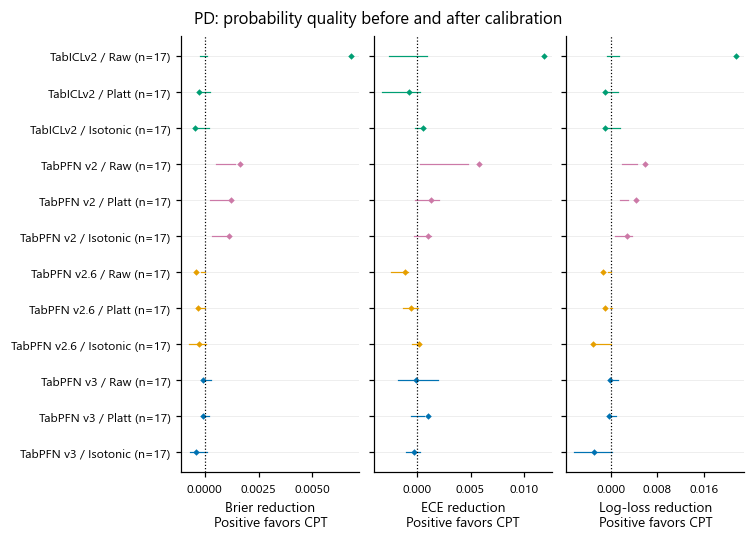

PD. Changes in the displayed outer-test probability-quality scores for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) relative to its untuned base. Positive reductions favor continued pretraining (CPT). Raw probabilities and validation-fitted Platt and isotonic calibration use a common dataset cohort within each base: all 9 scores require the same five completed, matched outer folds. Diamonds show equal-dataset means; horizontal lines span dataset quartiles, not confidence intervals. Log loss, when exported, is in nats; ECE depends on the binning scheme.

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,Reference CPT,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,verified,"Five folds; matched row identities, targets an..."
64,TabPFN v3,Cobranded,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
65,TabPFN v3,Home Credit,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
66,TabPFN v3,LendingClub,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,730176,0.138105,0.135123,0.132569,-0.002982,-0.005536,-0.002554,0.080536,0.080619,-0.000083,-0.002554,0.019772,0.009558
1,TabICLv2,HMEQ,0,Reference CPT,5960,0.199497,0.190717,0.192194,-0.008779,-0.007303,0.001476,0.017686,0.018154,-0.000468,0.001476,0.034721,0.011352
2,TabICLv2,MicroFinance,0,Reference CPT,158700,0.378091,0.364956,0.364263,-0.013134,-0.013828,-0.000693,0.218164,0.218413,-0.000249,-0.000693,0.028269,0.021001
3,TabICLv2,Thomas,0,Reference CPT,1225,0.263673,0.247090,0.244012,-0.016584,-0.019662,-0.003078,0.183083,0.183146,-0.000063,-0.003078,0.014727,0.010257
4,TabICLv2,GMSC,1,Reference CPT,150000,0.066840,0.057865,0.056626,-0.008975,-0.010214,-0.001239,0.049076,0.049166,-0.000090,-0.001239,0.007366,0.003548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,105471,0.092755,0.075083,0.077348,-0.017673,-0.015407,0.002265,0.082365,0.082222,0.000144,0.002265,0.007568,0.005367
64,TabPFN v3,Cobranded,3,Reference CPT,80000,0.246213,0.234716,0.236553,-0.011496,-0.009659,0.001837,0.130932,0.130591,0.000341,0.001837,0.017345,0.009891
65,TabPFN v3,Home Credit,3,Reference CPT,307511,0.080729,0.066750,0.068345,-0.013979,-0.012384,0.001595,0.068395,0.068366,0.000030,0.001595,0.009478,0.005742
66,TabPFN v3,LendingClub,3,Reference CPT,9578,0.160054,0.140981,0.138785,-0.019073,-0.021269,-0.002196,0.126388,0.126412,-0.000024,-0.002196,0.011739,0.008609


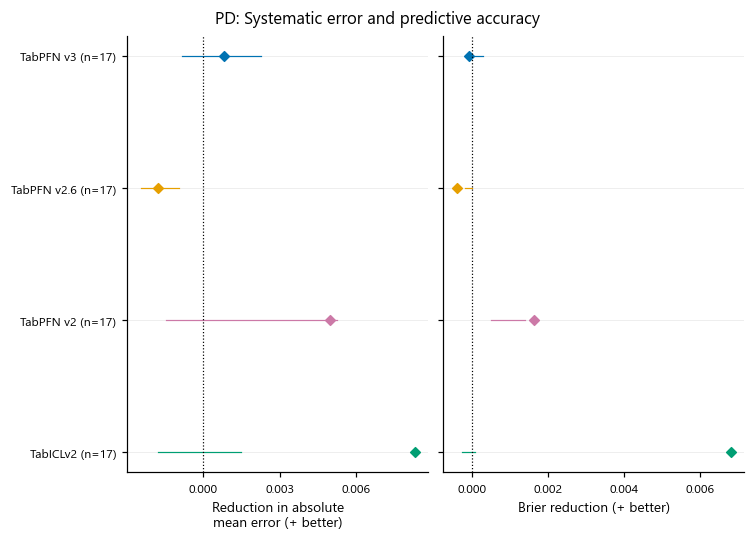

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

In [6]:
cp.show(sink, dg.plot_calibration_overview(run), track=run.track)
prediction_values, prediction_coverage = pred.analyze(run, reference=True)
report.table('Saved prediction coverage: fixed reference', prediction_coverage)
report.table('Paired per-table prediction diagnostics: fixed reference', prediction_values)
cp.show(sink, pred.plot_diagnostics(prediction_values, TRACK, coverage=prediction_coverage), track=TRACK)
report.add('5. Probability quality and prediction shifts', 'Brier score combines discrimination and calibration; ECE depends on its bins. The calibration overview compares the same tables across raw, Platt and isotonic scores; threshold-dependent F1 and ranking PR-AUC are included in the fixed-reference metric table.' + '\n' + pred.NOTE)

## 6. Fixed-context monitors, controls and cost

Monitoring uses fixed contexts during training and is distinct from the final five-fold benchmark above. Plot score change against learning rate, so both axes communicate a CPT choice or its effect. Separate legend boxes define learning rate, anchoring and update scope. Classical controls contextualize predictive performance; cost remains a compact table.

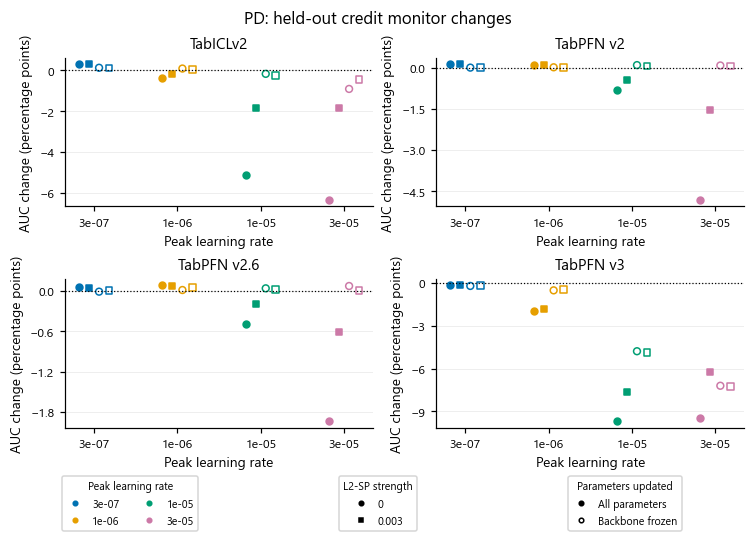

PD. Held-out credit fixed-context monitors at 10,000 successful updates, paired with update zero. 17 complete tables per model. Each mark is an equal-table mean for one rate, anchoring and update-scope combination on a recipe-complete cohort. Horizontal offsets separate the four combinations at each rate; they have no quantitative meaning. Colors encode rate, circle/square encodes L2-SP, and filled/open marks encode full/frozen-backbone updates. Zero means unchanged score. Vertical scales vary by base to expose small effects. These fixed-context monitoring measurements are separate from the final five-fold benchmark.

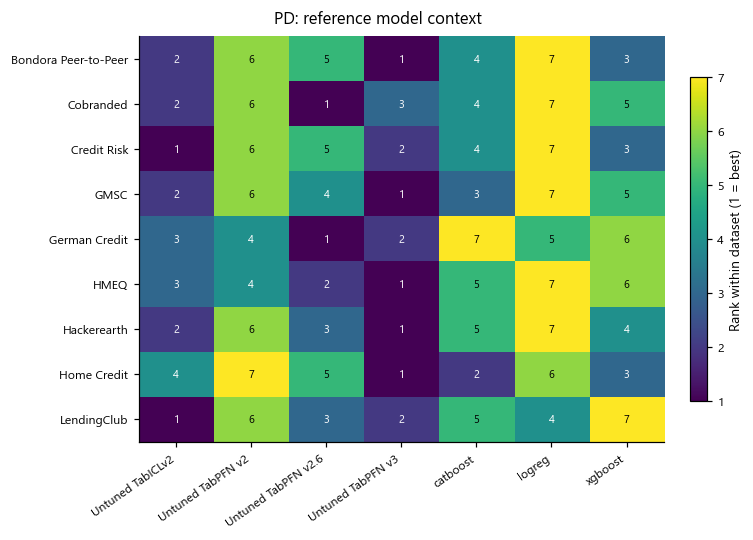

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

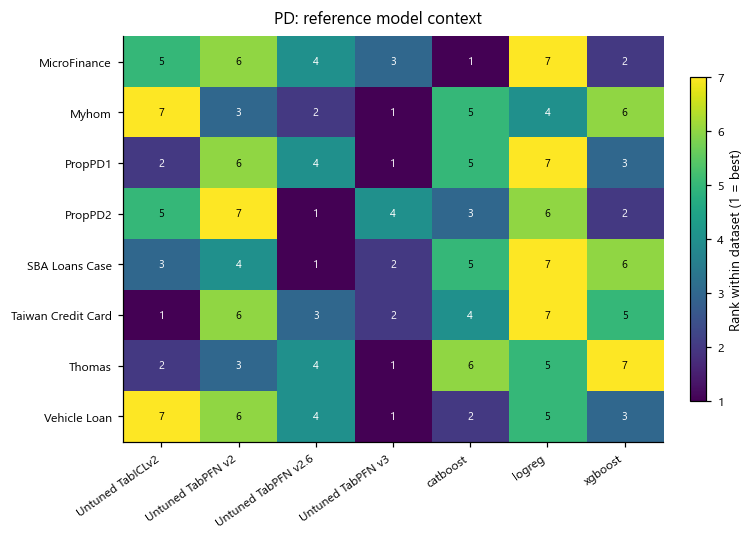

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

,"('elapsed_sec', 'count')","('elapsed_sec', 'median')","('elapsed_sec', 'min')","('elapsed_sec', 'max')","('sec_per_step', 'count')","('sec_per_step', 'median')","('sec_per_step', 'min')","('sec_per_step', 'max')","('peak_gpu_gb', 'count')","('peak_gpu_gb', 'median')",...,"('rows_seen', 'min')","('rows_seen', 'max')","('trainable_params', 'count')","('trainable_params', 'median')","('trainable_params', 'min')","('trainable_params', 'max')","('final_drift', 'count')","('final_drift', 'median')","('final_drift', 'min')","('final_drift', 'max')"
"('TabICLv2', False)",32,5880.051329,5388.954923,6227.217700,32,0.588005,0.538895,0.622722,32,27.1190,...,168231937,195157151,32,27552250.0,27552250,27552250,32,0.003687,0.001127,0.028629
"('TabICLv2', True)",32,5641.459922,5191.705577,5953.787302,32,0.564146,0.519171,0.595379,32,26.7075,...,168231937,195157151,32,1818106.0,1818106,1818106,32,0.006402,0.001463,0.042363
"('TabPFN v2', False)",32,4989.562487,4558.125119,5434.754171,32,0.498956,0.455813,0.543475,32,181.0705,...,74887937,84373151,32,7244554.0,7244554,7244554,32,0.004249,0.001053,0.028788
"('TabPFN v2', True)",32,4818.276219,4399.349810,5211.900758,32,0.481828,0.439935,0.521190,32,108.1805,...,74887937,84373151,32,166666.0,166666,166666,32,0.006800,0.001252,0.078394
"('TabPFN v2.6', False)",32,4264.081141,3931.728692,4570.578204,32,0.426408,0.393173,0.457058,32,128.4200,...,80721937,91297151,32,10732042.0,10732042,10732042,32,0.003833,0.000877,0.040765
"('TabPFN v2.6', True)",32,3799.214932,3556.330243,4103.147097,32,0.379921,0.355633,0.410315,32,80.4470,...,80721937,91297151,32,101386.0,101386,101386,32,0.001670,0.000229,0.015853
"('TabPFN v3', False)",32,5222.860977,4837.436067,5610.246155,32,0.522286,0.483744,0.561025,32,121.0455,...,168231937,195157151,32,53153136.0,53153136,53153136,32,0.006299,0.001484,0.052170
"('TabPFN v3', True)",32,4818.272543,4506.762127,5040.165402,32,0.481827,0.450676,0.504017,32,109.9990,...,168231937,195157151,32,1795440.0,1795440,1795440,32,0.006421,0.001305,0.037843


In [7]:
cp.show(sink, ce.plot_monitor_changes(run), track=TRACK)
cp.show(sink, cp.plot_control_context(run), track=TRACK)
report.table('Completed-trial computational cost', pub.cost_summary(run))
report.add('6. Fixed-context monitors, controls and cost', 'Monitor changes pair each excluded credit table with its own update-zero score, then average tables equally. Monitor and final benchmark results answer related but distinct measurement questions. One main training seed and overlapping adaptation corpora limit independence claims.')

## Complete text summary

Every displayed value, table and caption, in section order. Detailed table effects remain available even where compact figures replace repeated panels.

In [8]:
print(report.summary(sink))

Experiment 1: PD outcomes and evaluation

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.

1. Evidence and benchmark eligibility
Run cpt_main_v5; PD; 256 planned trials; target 10,000 successful updates.
status
OK    256
1536 trajectory records; 11715 benchmark fold records.
PENDING means no recorded outcome; it can include running or queued work. This is not live scheduler state.

Table: Available evidence
CSV (first column: row index)
row,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project traj